In [1]:
import tensorflow as tf

print(tf.__version__)
print(tf.config.list_physical_devices('GPU'))


2.21.0
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [5]:

import pandas as pd
import urllib.request
import zipfile

url = "https://archive.ics.uci.edu/static/public/235/individual+household+electric+power+consumption.zip"

print("Downloading dataset...")

urllib.request.urlretrieve(url, "electricity.zip")

print("Download completed!")

with zipfile.ZipFile("electricity.zip", "r") as z:
    with z.open("household_power_consumption.txt") as f:
        df = pd.read_csv(
            f,
            sep=";",
            nrows=10000,
            na_values=["?"],
            low_memory=False
        )

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print(df.head())

Download completed!
Dataset loaded successfully!
Shape: (10000, 9)
         Date      Time  Global_active_power  Global_reactive_power  Voltage  \
0  16/12/2006  17:24:00                4.216                  0.418   234.84   
1  16/12/2006  17:25:00                5.360                  0.436   233.63   
2  16/12/2006  17:26:00                5.374                  0.498   233.29   
3  16/12/2006  17:27:00                5.388                  0.502   233.74   
4  16/12/2006  17:28:00                3.666                  0.528   235.68   

   Global_intensity  Sub_metering_1  Sub_metering_2  Sub_metering_3  
0              18.4             0.0             1.0            17.0  
1              23.0             0.0             1.0            16.0  
2              23.0             0.0             2.0            17.0  
3              23.0             0.0             1.0            17.0  
4              15.8             0.0             1.0            17.0  


In [6]:

import pandas as pd
import numpy as np

# Convert measurement columns to numeric
cols = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

for col in cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Check missing values
print("Missing values before cleaning:")
print(df[cols].isnull().sum())

# Fill missing values
df[cols] = df[cols].ffill().bfill()

print("\nMissing values after cleaning:")
print(df[cols].isnull().sum())

print("\nDataset shape:", df.shape)

Missing values before cleaning:
Global_active_power      2
Global_reactive_power    2
Voltage                  2
Global_intensity         2
Sub_metering_1           2
Sub_metering_2           2
Sub_metering_3           2
dtype: int64

Missing values after cleaning:
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
dtype: int64

Dataset shape: (10000, 9)


In [8]:

from sklearn.preprocessing import MinMaxScaler

data = df[["Global_active_power"]].values

scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(data)

print("Original values:")
print(data[:5])

print("\nNormalized values:")
print(scaled_data[:5])

print("Normalization completed!")

Original values:
[[4.216]
 [5.36 ]
 [5.374]
 [5.388]
 [3.666]]

Normalized values:
[[0.52301691]
 [0.67178153]
 [0.67360208]
 [0.67542263]
 [0.45149545]]
Normalization completed!


In [9]:

split = int(len(scaled_data) * 0.8)

train_data = scaled_data[:split]
test_data = scaled_data[split:]

print("Training records:", len(train_data))
print("Testing records:", len(test_data))

Training records: 8000
Testing records: 2000


In [10]:

import numpy as np

def create_sequences(data, time_steps=60):
    X, y = [], []

    for i in range(time_steps, len(data)):
        X.append(data[i-time_steps:i, 0])
        y.append(data[i, 0])

    return np.array(X), np.array(y)

# Create training sequences
X_train, y_train = create_sequences(train_data)

# Use the last 60 training records as context
test_with_context = np.concatenate(
    [train_data[-60:], test_data]
)

# Create testing sequences
X_test, y_test = create_sequences(test_with_context)

# Reshape for LSTM input
X_train = X_train.reshape(X_train.shape[0], 60, 1)
X_test = X_test.reshape(X_test.shape[0], 60, 1)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (7940, 60, 1)
y_train shape: (7940,)
X_test shape: (2000, 60, 1)
y_test shape: (2000,)


In [11]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

model = Sequential([
    LSTM(50, return_sequences=True,
         input_shape=(60, 1)),
    Dropout(0.2),

    LSTM(50),
    Dropout(0.2),

    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,651 (119.73 KB)

 Trainable params: 30,651 (119.73 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:

from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - loss: 0.0122 - val_loss: 0.0032
Epoch 2/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0062 - val_loss: 0.0022
Epoch 3/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0056 - val_loss: 0.0019
Epoch 4/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0051 - val_loss: 0.0018
Epoch 5/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0051 - val_loss: 0.0017
Epoch 6/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0050 - val_loss: 0.0017
Epoch 7/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0047 - val_loss: 0.0015
Epoch 8/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0047 - val_loss: 0.0015
Epoch 9/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0046 - val_loss: 0.0014
Epoch 10/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0046 - val_loss: 0.0013
Epoch 11/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0045 - val_loss: 0.0013
Epoch 12/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 

In [13]:


import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Predict electricity consumption
pred_scaled = model.predict(X_test)

# Convert normalized values back to kW
predicted = scaler.inverse_transform(pred_scaled)
actual = scaler.inverse_transform(y_test.reshape(-1, 1))

# Calculate evaluation metrics
mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

print("Mean Absolute Error (MAE):", round(mae, 4), "kW")
print("Root Mean Squared Error (RMSE):", round(rmse, 4), "kW")

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step
Mean Absolute Error (MAE): 0.5157 kW
Root Mean Squared Error (RMSE): 0.7391 kW


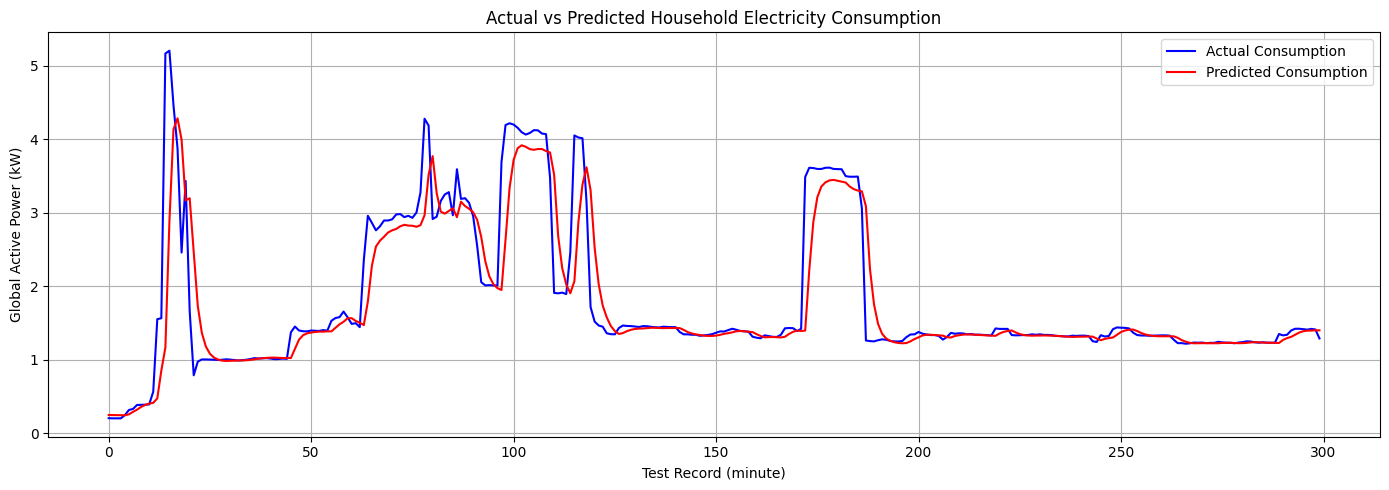

In [14]:

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(actual[:300], label="Actual Consumption", color="blue")
plt.plot(predicted[:300], label="Predicted Consumption", color="red")

plt.title("Actual vs Predicted Household Electricity Consumption")
plt.xlabel("Test Record (minute)")
plt.ylabel("Global Active Power (kW)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [16]:

# Save the trained LSTM model
model.save("household_electricity_lstm.keras")

print("Model saved successfully!")

Model saved successfully!


In [17]:

from google.colab import files

files.download("household_electricity_lstm.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:

files.download("actual_vs_predicted.png")

FileNotFoundError: Cannot find file: actual_vs_predicted.png

In [19]:

files.download("actual_vs_predicted.png")


FileNotFoundError: Cannot find file: actual_vs_predicted.png

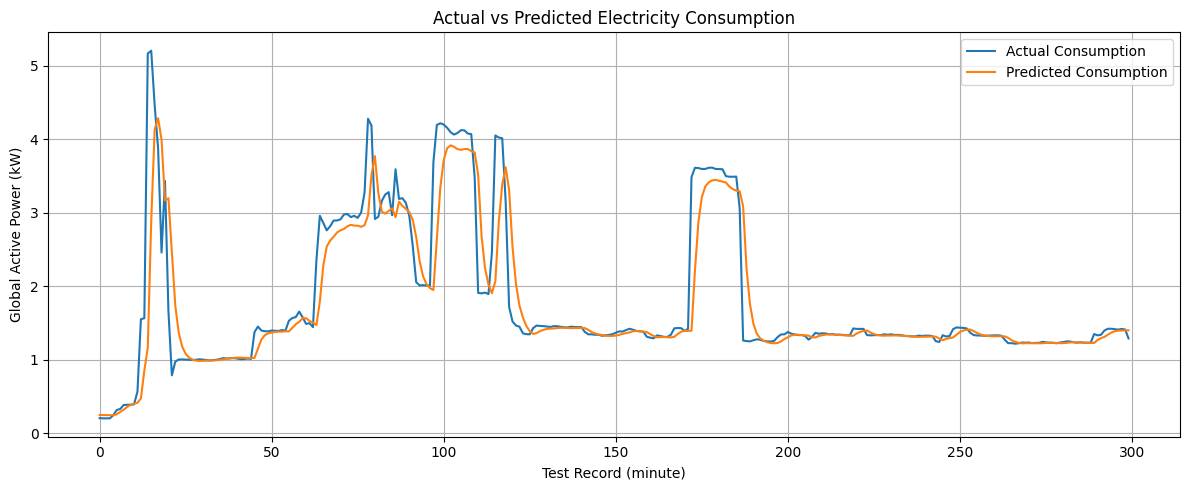

Graph saved: True


In [20]:

import matplotlib.pyplot as plt
import os

plt.figure(figsize=(12, 5))

plt.plot(actual[:300].flatten(), label="Actual Consumption")
plt.plot(predicted[:300].flatten(), label="Predicted Consumption")

plt.title("Actual vs Predicted Electricity Consumption")
plt.xlabel("Test Record (minute)")
plt.ylabel("Global Active Power (kW)")
plt.legend()
plt.grid(True)
plt.tight_layout()

# Save image
graph_path = "/content/actual_vs_predicted.png"
plt.savefig(graph_path, dpi=300, bbox_inches="tight")
plt.show()

print("Graph saved:", os.path.exists(graph_path))

In [21]:

from google.colab import files

files.download("/content/actual_vs_predicted.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

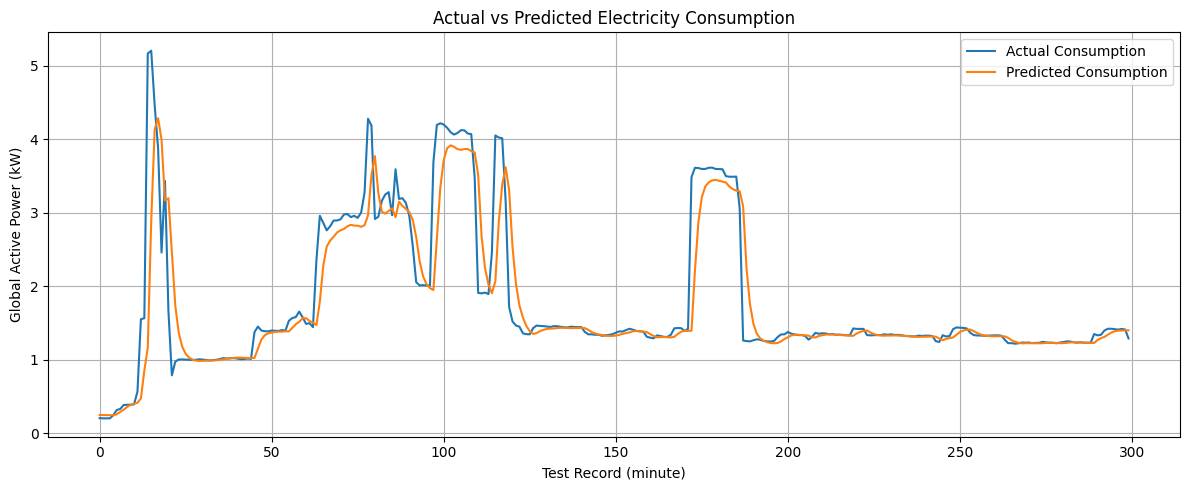

Graph saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:

import matplotlib.pyplot as plt
from google.colab import files
import os

# Create graph
plt.figure(figsize=(12, 5))
plt.plot(actual[:300].flatten(), label="Actual Consumption")
plt.plot(predicted[:300].flatten(), label="Predicted Consumption")

plt.title("Actual vs Predicted Electricity Consumption")
plt.xlabel("Test Record (minute)")
plt.ylabel("Global Active Power (kW)")
plt.legend()
plt.grid(True)
plt.tight_layout()

# Save to Colab's working directory
filename = "/content/actual_vs_predicted.png"
plt.savefig(filename, dpi=300, bbox_inches="tight")
plt.show()

# Verify and download
if os.path.exists(filename):
    print("Graph saved successfully!")
    files.download(filename)
else:
    print("Graph file was not created.")

In [24]:

from google.colab import files

files.download("/content/actual_vs_predicted.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:

from google.colab import files

files.download("/content/actual_vs_predicted.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:

# Test the trained LSTM model with a new example

# Example: 60 minutes of electricity consumption
# Use the last 60 unseen test measurements as input
example_input = test_with_context[-60:].reshape(1, 60, 1)

# Predict the next minute
prediction_scaled = model.predict(example_input, verbose=0)

# Convert prediction back to kW
prediction_kw = scaler.inverse_transform(prediction_scaled)

print("Example Input: Previous 60 minutes of electricity consumption")
print("Predicted next-minute consumption:", round(float(prediction_kw[0, 0]), 3), "kW")

Example Input: Previous 60 minutes of electricity consumption
Predicted next-minute consumption: 4.407 kW


In [27]:
# Calculate approximate normalized MAE percentage
mean_actual = np.mean(actual)

mae_percentage = (mae / mean_actual) * 100
approx_accuracy = 100 - mae_percentage

print("Mean actual consumption:", round(float(mean_actual), 4), "kW")
print("Normalized MAE:", round(float(mae_percentage), 2), "%")
print("Approximate accuracy:", round(float(approx_accuracy), 2), "%")

Mean actual consumption: 2.442 kW
Normalized MAE: 21.12 %
Approximate accuracy: 78.88 %
